In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy import integrate
from matplotlib.colors import LogNorm
import matplotlib.colors as mcolors
from scipy.special import erf
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

# Set the default figure size for all plots in inches (width, height)
plt.rcParams['figure.figsize'] = (10, 6) 

# Optionally, you can also increase the default DPI (dots per inch) for higher resolution
plt.rcParams['figure.dpi'] = 150 

In [150]:
def C_y(etas,thetas,eta_0,n_terms):
    c = np.zeros((len(thetas),len(etas)))
    c_1 = 1+2*np.sum(np.exp(-(np.arange(1,n_terms+1)*np.pi)**2*thetas[:,None,None])
                     *np.cos(np.arange(1,n_terms+1)*np.pi*(eta_0+1/2))
                     *np.cos(np.arange(1,n_terms+1)*np.pi*(etas[None,:,None]+1/2)),axis = -1)
    z = (etas[None,:,None]-(-1)**np.abs(np.arange(-n_terms//2,n_terms//2+1))*eta_0+np.arange(-n_terms//2,n_terms//2+1))
    c_2 = 1/np.sqrt(4*np.pi*thetas)[:,None]*np.sum(np.exp(-z**2/(4*thetas)[:,None,None]),axis = -1)
    c[thetas<=1/(np.pi**2)] = c_2[thetas<=1/(np.pi**2)]
    c[thetas>1/(np.pi**2)] = c_1[thetas>1/(np.pi**2)]
    return c
def C_y_int(etas,thetas,eta_0,n_terms):
    c = np.zeros((len(thetas),len(etas)))
    c_1 = thetas[:,None]+2*np.sum(1/(np.arange(1,n_terms+1)*np.pi)**2*(1-np.exp(-(np.arange(1,n_terms+1)*np.pi)**2*thetas[:,None,None]))
                     *np.cos(np.arange(1,n_terms+1)*np.pi*(eta_0+1/2))
                     *np.cos(np.arange(1,n_terms+1)*np.pi*(etas[None,:,None]+1/2)),axis = -1)
    z = (etas[None,:,None]-(-1)**np.abs(np.arange(-n_terms//2,n_terms//2+1))*eta_0+np.arange(-n_terms//2,n_terms//2+1))
    c_2 = np.sum(np.sqrt(thetas/np.pi)[:,None,None]*np.exp(-z**2/(4*thetas)[:,None,None])
                 -np.abs(z)/2*(1-erf(np.abs(z)/(2*np.sqrt(thetas)[:,None,None]))),axis = -1)
    c[thetas<=1/(np.pi**2)] = c_2[thetas<=1/(np.pi**2)]
    c[thetas>1/(np.pi**2)] = c_1[thetas>1/(np.pi**2)]
    return c
def v_y (eta, a):
    v_y = (a+1)/a*(1 - abs(2*((eta+1/2)%1.0-1/2))**a)
    return v_y
def Expected_position(etas,thetas,eta_0,n_terms,a,concs,n_etas_prime):
    etas_prime_0n = (-1)**np.abs(np.arange(-n_terms//2,n_terms//2+1))*eta_0-np.arange(-n_terms//2,n_terms//2+1)
    exp_pos = np.zeros((len(thetas),len(etas)))
    for i,theta in enumerate(thetas):
        deta_prime = (np.sqrt(theta)+np.abs((etas[:,None]-etas_prime_0n[None,:])/2))/n_etas_prime
        etas_prime = (etas[:,None,None]+etas_prime_0n[None,:,None])/2+deta_prime[:,:,None]*np.arange(-2*n_etas_prime,2*n_etas_prime+1)[None,None,:]
        arg_1 = ((np.abs(etas_prime-etas_prime_0n[None,:,None])
                     +np.abs(etas_prime-etas[:,None,None]))
                    /np.sqrt(4*theta))
        arg_2 = -(etas[:,None,None]-etas_prime_0n[None,:,None])**2/(4*theta)
        p_int_primary = (np.sqrt(np.pi*theta/4)*
             (1-erf(arg_1))
             /np.exp(arg_2))
        p_int_alt = (np.sqrt(np.pi*theta/4)*np.exp(-arg_1**2-arg_2)/(np.sqrt(np.pi)*arg_1))

        p_int = np.where(arg_1<6.0,p_int_primary,p_int_alt)
            
        w_n = np.exp(-(etas[:,None]-etas_prime_0n[None,:])**2/(4*theta))
        w_n = w_n/np.sum(w_n,axis = -1)[:,None]
        exp_pos[i] =  np.sum(w_n*(np.sum(p_int*v_y(etas_prime,a),axis = -1)*deta_prime),axis = -1)
    return exp_pos*concs
def Effective_Velocity(etas,a,concs):
    v_eff = np.trapezoid(concs*v_y(etas,a),etas,axis = 1)/np.trapezoid(concs,etas,axis = 1)
    return v_eff
def Effective_Dispersion(etas,thetas,eta_0,n_terms,a,concs,n_etas_prime):
    exp_pos = Expected_position(etas,thetas,eta_0,n_terms,a,concs,n_etas_prime)
    term_1 = np.trapezoid(exp_pos*v_y(etas,a),x = etas,axis = 1)/np.trapezoid(concs,etas,axis = 1)
    v_eff = Effective_Velocity(etas,a,concs)
    term_2 = v_eff*cumulative_trapezoid(v_eff,x=thetas,axis = 0, initial = 0.0)
    D_eff = term_1-term_2
    return D_eff

from scipy.special import erf


def Effective_Dispersion_uniform(thetas,a, N=1000,extra_fac = 10):

    eta1 = np.linspace(-1/2, 1/2, N+1)
    eta2 = np.linspace(-extra_fac/2, extra_fac/2, extra_fac*N+1)
    deta = eta1[1] - eta1[0]

    v1 = v_y(eta1,a)
    v2 = v_y(eta2,a)

    # Pairwise distances
    R = np.abs(eta1[:, None] - eta2[None, :])

    # Weight matrix
    W = np.outer(v1, v2)

    K = (
            np.sqrt(thetas[:,None,None]/(np.pi))
            * np.exp(-R**2/(4*thetas[:,None,None]))
            - R/(2)
            * (1 - erf(R/np.sqrt(4*thetas[:,None,None])))
        )
    results = (deta**2) * np.sum(W*K,axis = (1,2))

    return results

In [151]:
mean_a = 2.37
sigma_a = 0.48

In [189]:
thetas = np.linspace(0,0.3,600)+10**-6
n_terms = 10
Neta = 400
etas = np.linspace(-1/2,1/2,Neta)#np.linspace(-1/2,1/2,2*Neta+1)[1::2]
a_s = np.linspace(1.0,8.0,17)

1.000117826948248
0.9996612306407431
0.9994484852033504
0.9991883110935581
0.9988611192766308
0.9984590281158723
0.9979744898006864
0.9973999529626654
0.9967278697627624
0.9959506963394804
0.9950608915829999
0.9940509162400271
0.9929132323582496
0.9916403029390739
0.9902245917151455
0.9886585630077296
0.9869346816324821
CPU times: total: 9min 22s
Wall time: 9min 25s


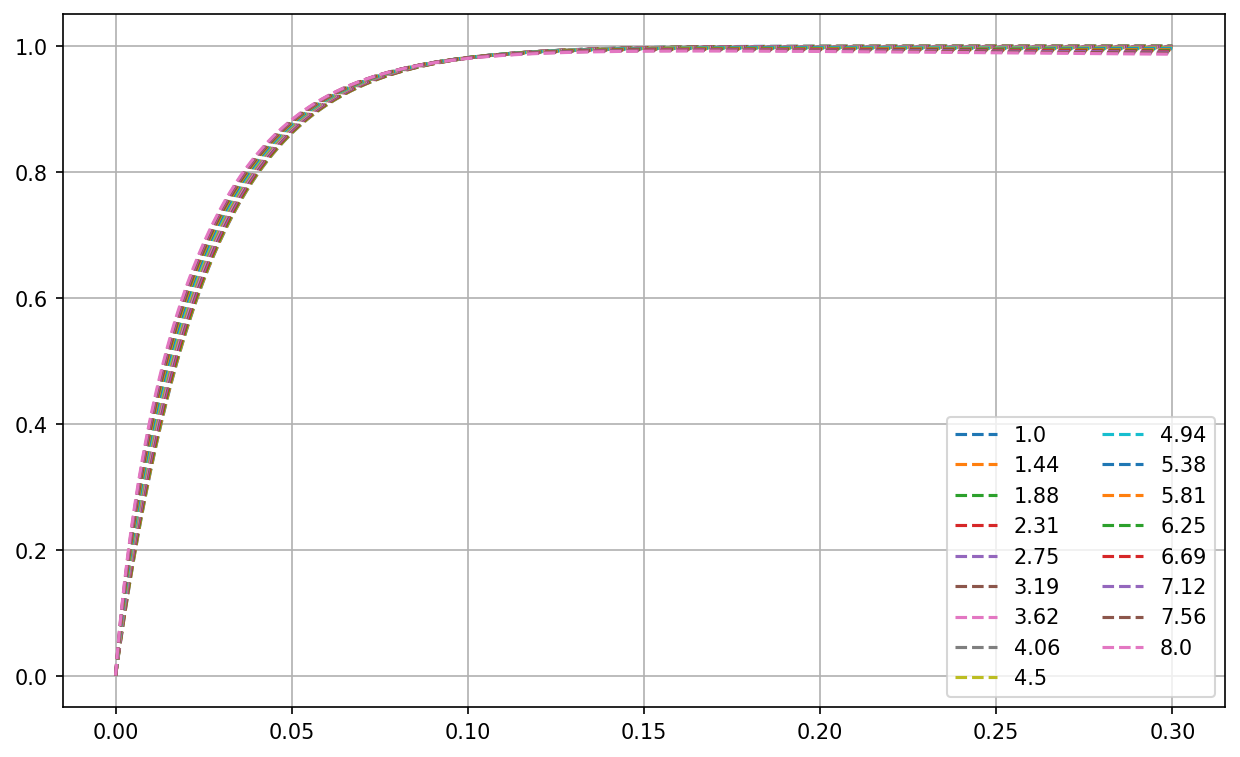

In [190]:
%%time
D_effs_uniform = np.zeros((len(a_s),len(thetas)))
for i,a in enumerate(a_s):
    D_eff = np.concatenate([(Effective_Dispersion_uniform(thetas_i,a, N=Neta,extra_fac = n_terms)-thetas_i) for thetas_i in thetas.reshape((10,-1))])
    D_effs_uniform[i] = D_eff
    plt.plot(thetas,D_eff*(6*(2*a**2+9*a+9)),c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],linestyle = 'dashed',label = str(round(a,2)))
    print(D_eff[-1]*(6*(2*a**2+9*a+9)))
plt.grid()
plt.legend(ncol=2)

C:\Users\manue\AppData\Local\Temp\ipykernel_17764\464447409.py:35: RuntimeWarning: invalid value encountered in divide
  p_int_primary = (np.sqrt(np.pi*theta/4)*
C:\Users\manue\AppData\Local\Temp\ipykernel_17764\464447409.py:43: RuntimeWarning: invalid value encountered in divide
  w_n = w_n/np.sum(w_n,axis = -1)[:,None]


0.9903907049403249
0.9890468441882831
0.9869736387954888
0.984569537457513
0.9819543182991423
0.9791639098404988
0.976210908553414
0.9731013987063978
0.9698396876822091
0.9664296745260862
0.962875238260568
0.9591803302134805
0.9553489769212807
0.9513852584738551
0.9472932830468589
0.9430771639735299
0.9387410009055386
CPU times: total: 10min 2s
Wall time: 10min 5s


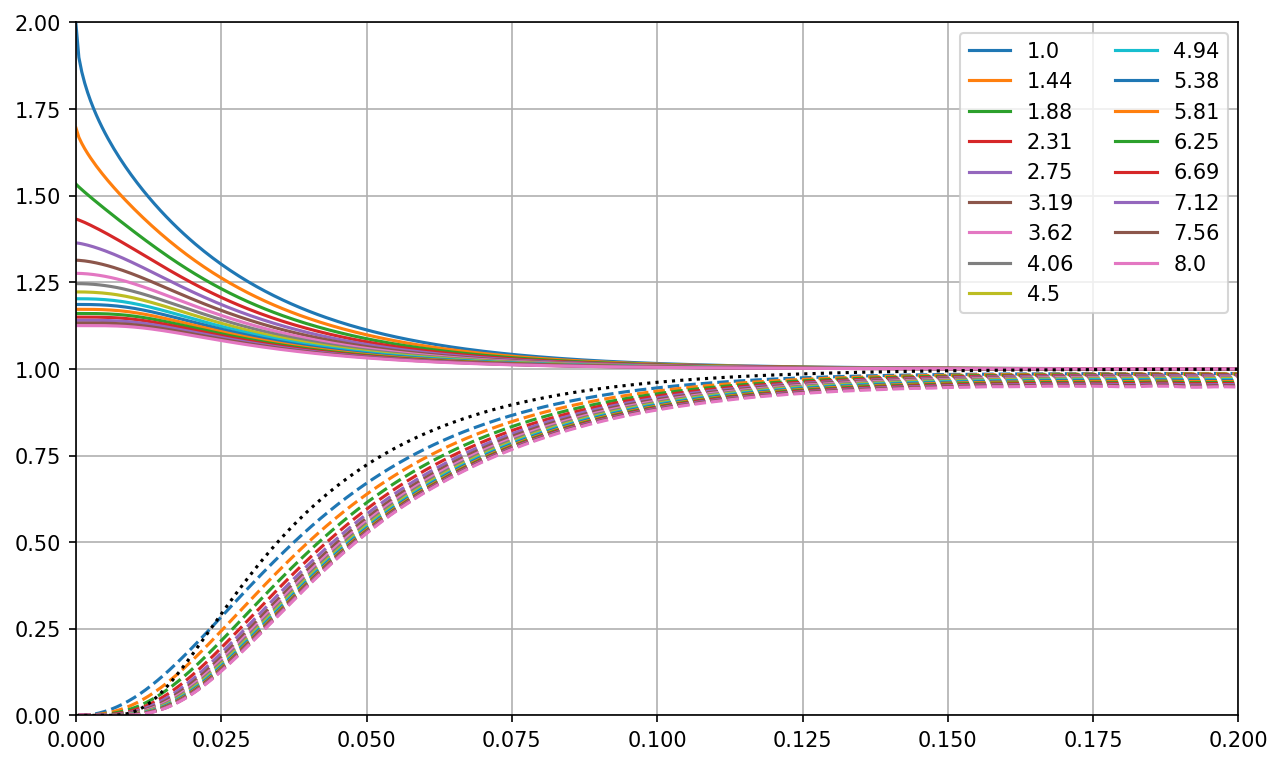

In [191]:
%%time
eta_0 = 0.0
concs = C_y(etas,thetas,eta_0,n_terms)
v_effs_central = np.zeros((len(a_s),len(thetas)))
D_effs_central = np.zeros((len(a_s),len(thetas)))
for i,a in enumerate(a_s):
    v_eff = Effective_Velocity(etas,a,concs)
    v_effs_central[i] = v_eff
    D_eff = Effective_Dispersion(etas,thetas,eta_0,n_terms,a,concs,30)
    D_effs_central[i] = D_eff
    plt.plot(thetas,v_eff, c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],label = str(round(a,2)))
    plt.plot(thetas,D_eff*(6*(2*a**2+9*a+9)),c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],linestyle = 'dashed')
    print(D_eff[-1]*(6*(2*a**2+9*a+9)))
k_effs_central = (concs[:,0]+concs[:,-1])/2
plt.plot(thetas,(concs[:,0]+concs[:,-1])/2, c = 'k', linestyle = 'dotted')
plt.ylim(0,2)
plt.xlim(0,0.2)
plt.grid()
plt.legend(ncol=2)

C:\Users\manue\AppData\Local\Temp\ipykernel_17764\464447409.py:35: RuntimeWarning: invalid value encountered in divide
  p_int_primary = (np.sqrt(np.pi*theta/4)*
C:\Users\manue\AppData\Local\Temp\ipykernel_17764\464447409.py:38: RuntimeWarning: divide by zero encountered in divide
  p_int_alt = (np.sqrt(np.pi*theta/4)*np.exp(-arg_1**2-arg_2)/(np.sqrt(np.pi)*arg_1))
C:\Users\manue\AppData\Local\Temp\ipykernel_17764\464447409.py:43: RuntimeWarning: invalid value encountered in divide
  w_n = w_n/np.sum(w_n,axis = -1)[:,None]


0.9983915210455407
0.9976724188093685
0.997118545662098
0.9966085335486538
0.9961559891481899
0.9957871479973741
0.9955277350607967
0.9954022230024617
0.9954340677169238
0.9956458632425083
0.996059432404491
0.9966958967341903
0.9975757388825396
0.9987188592774083
1.000144626424308
1.0018719203901794
1.0039191695334446
CPU times: total: 10min 1s
Wall time: 10min 4s


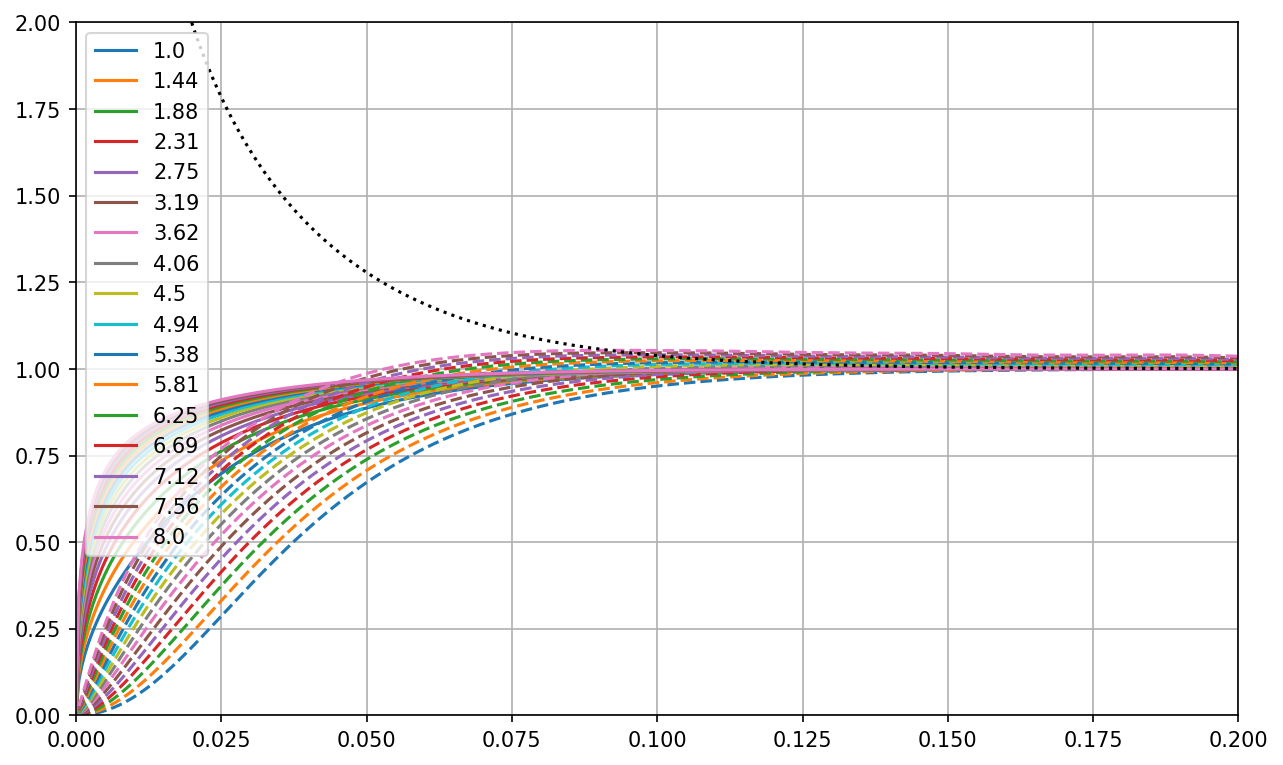

In [192]:
%%time
eta_0 = 0.5
concs1 = C_y(etas,thetas,eta_0,n_terms)
concs2 = C_y(etas,thetas,-eta_0,n_terms)
concs = (concs1+concs2)/2
v_effs_bound = np.zeros((len(a_s),len(thetas)))
D_effs_bound = np.zeros((len(a_s),len(thetas)))
for i,a in enumerate(a_s):
    v_eff = Effective_Velocity(etas,a,concs)
    v_effs_bound[i] = v_eff
    D_eff = Effective_Dispersion(etas,thetas,eta_0,n_terms,a,concs1,30)
    D_effs_bound[i] = D_eff
    plt.plot(thetas,v_eff, c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],label = str(round(a,2)))
    plt.plot(thetas,D_eff*(6*(2*a**2+9*a+9)),c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],linestyle = 'dashed')
    print(D_eff[-1]*(6*(2*a**2+9*a+9)))
k_effs_bound = (concs[:,0]+concs[:,-1])/2
plt.plot(thetas,(concs[:,0]+concs[:,-1])/2, c = 'k', linestyle = 'dotted')
plt.ylim(0,2)
plt.xlim(0,0.2)
plt.grid()
plt.legend()

In [210]:
D_effs_central[:,0] = 0.0
D_effs_bound[:,0] = 0.0
D_effs_uniform[:,0] = 0.0

In [211]:
v_effs_uniform = np.ones((len(a_s),len(thetas)))
k_effs_uniform = np.ones((len(thetas)))

In [212]:
np.savez_compressed(
    "effective_params.npz",
    thetas=thetas,
    a_s = a_s,
    v_effs_central=v_effs_central,
    D_effs_central=D_effs_central,
    k_effs_central=k_effs_central,
    v_effs_bound=v_effs_bound,
    D_effs_bound=D_effs_bound,
    k_effs_bound=k_effs_bound,
    v_effs_uniform=v_effs_uniform,
    D_effs_uniform=D_effs_uniform,
    k_effs_uniform=k_effs_uniform 
)

In [195]:
# data = np.load("effective_params.npz")

# thetas = data["thetas"]
# a_s = data["a_s"]
# v_effs_central = data["v_effs_central"]
# D_effs_central = data["D_effs_central"]
# k_effs_central = data["k_effs_central"]
# v_effs_bound = data["v_effs_bound"]
# D_effs_bound = data["D_effs_bound"]
# k_effs_bound = data["k_effs_bound"]

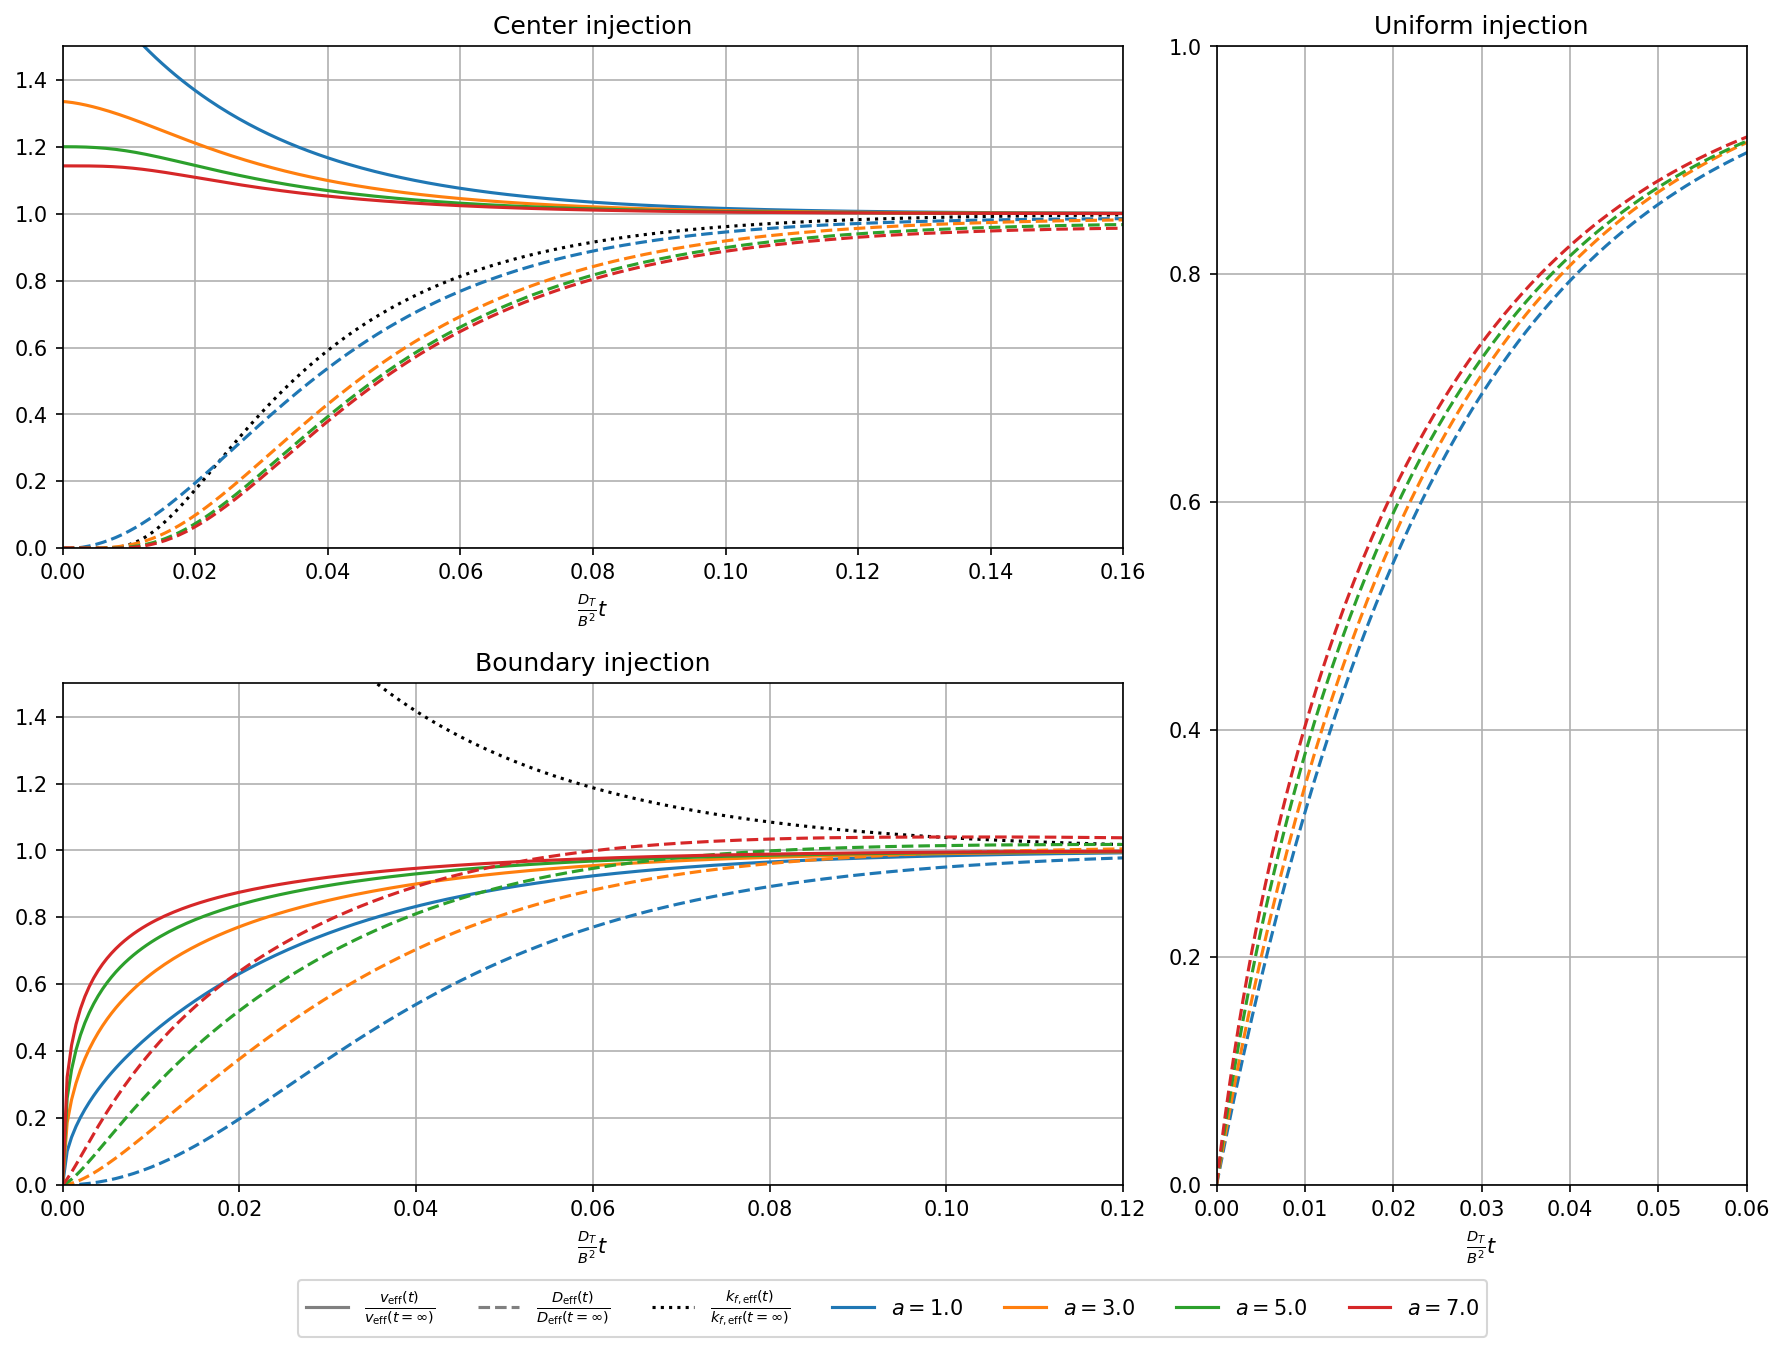

In [207]:
fig, axes = plt.subplot_mosaic([['A','C'],['B','C']],width_ratios = (3,1.5),figsize=(12, 9))
a_s_plot = [1.0,3.0,5.0,7.0]

ax = axes['A']
ax.plot(thetas,k_effs_central,c = 'k' ,linestyle = 'dotted')
for i,a in enumerate(a_s_plot):
    v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_central.T])
    ax.plot(thetas,v_effs_a, c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],label = str(a))
    D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_central.T])
    ax.plot(thetas,D_effs_a*(6*(2*a**2+9*a+9)), c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],linestyle = 'dashed')
ax.set_title('Center injection')
ax.set_xlabel(r"$\frac{D_T}{B^2}t$")
ax.set_ylim(0,1.5)
ax.set_xlim(0,0.16)
ax.grid()

ax = axes['B']
ax.plot(thetas,k_effs_bound,c = 'k' ,linestyle = 'dotted')
for i,a in enumerate(a_s_plot):
    v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_bound.T])
    ax.plot(thetas,v_effs_a, c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],label = str(a))
    D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_bound.T])
    ax.plot(thetas,D_effs_a*(6*(2*a**2+9*a+9)), c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],linestyle = 'dashed')
ax.set_title('Boundary injection')
ax.set_xlabel(r"$\frac{D_T}{B^2}t$")
ax.set_ylim(0,1.5)
ax.set_xlim(0,0.12)
ax.grid()

ax = axes['C']
for i,a in enumerate(a_s_plot):
    D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_uniform.T])
    ax.plot(thetas,D_effs_a*(6*(2*a**2+9*a+9)), c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],linestyle = 'dashed')
ax.set_title('Uniform injection')
ax.set_xlabel(r"$\frac{D_T}{B^2}t$")
ax.set_ylim(0,1)
ax.set_xlim(0,0.06)
ax.grid()

fig.legend(handles=[
        plt.Line2D([0], [0], c = 'gray', label=r"$\frac{v_{\mathrm{eff}}(t)}{v_{\mathrm{eff}}(t=\infty)}$"),
        plt.Line2D([0], [0], c = 'gray',linestyle = 'dashed', label=r"$\frac{D_{\mathrm{eff}}(t)}{D_{\mathrm{eff}}(t=\infty)}$"),
        plt.Line2D([0], [0], c = 'k',linestyle = 'dotted', label=r"$\frac{k_{f,\mathrm{eff}}(t)}{k_{f,\mathrm{eff}}(t=\infty)}$"),
        plt.Line2D([0], [0], color="tab:blue", label=r"$a=1.0$"),
        plt.Line2D([0], [0], color="tab:orange", label=r"$a=3.0$"),
        plt.Line2D([0], [0], color="tab:green", label=r"$a=5.0$"),
        plt.Line2D([0], [0], color="tab:red", label=r"$a=7.0$"),
        ], loc="lower center", ncol=7)
plt.tight_layout(rect=[0,0.04,1,1])

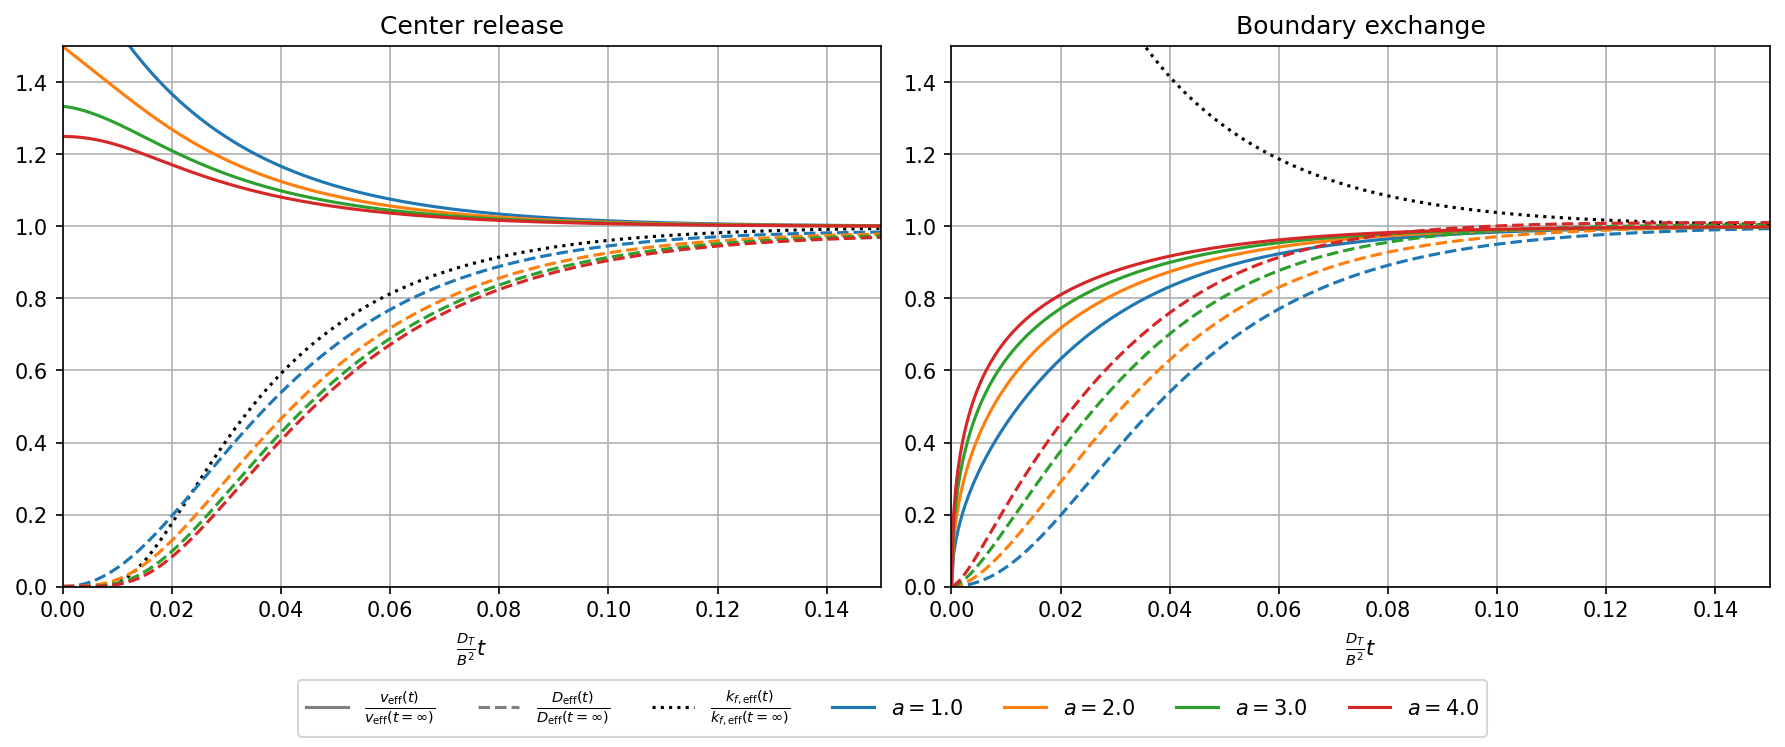

In [16]:
fig, ax = plt.subplots(ncols = 2, nrows = 1, figsize = (12,5))
a_s_plot = [1.0,2.0,3.0,4.0]

ax[0].plot(thetas,k_effs_central,c = 'k' ,linestyle = 'dotted')
for i,a in enumerate(a_s_plot):
    v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_central.T])
    ax[0].plot(thetas,v_effs_a, c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],label = str(a))
    D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_central.T])
    ax[0].plot(thetas,D_effs_a*(6*(2*a**2+9*a+9)), c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],linestyle = 'dashed')
ax[0].set_title('Center release')
ax[0].set_xlabel(r"$\frac{D_T}{B^2}t$")
ax[0].set_ylim(0,1.5)
ax[0].set_xlim(0,0.15)
ax[0].grid()

ax[1].plot(thetas,k_effs_bound,c = 'k' ,linestyle = 'dotted')
for i,a in enumerate(a_s_plot):
    v_effs_a = np.array([np.interp(a,a_s,v_eff) for v_eff in v_effs_bound.T])
    ax[1].plot(thetas,v_effs_a, c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],label = str(a))
    D_effs_a = np.array([np.interp(a,a_s,D_eff) for D_eff in D_effs_bound.T])
    ax[1].plot(thetas,D_effs_a*(6*(2*a**2+9*a+9)), c = list(mcolors.TABLEAU_COLORS)[i%len(list(mcolors.TABLEAU_COLORS))],linestyle = 'dashed')
ax[1].set_title('Boundary exchange')
ax[1].set_xlabel(r"$\frac{D_T}{B^2}t$")
ax[1].set_ylim(0,1.5)
ax[1].set_xlim(0,0.15)
ax[1].grid()

fig.legend(handles=[
        plt.Line2D([0], [0], c = 'gray', label=r"$\frac{v_{\mathrm{eff}}(t)}{v_{\mathrm{eff}}(t=\infty)}$"),
        plt.Line2D([0], [0], c = 'gray',linestyle = 'dashed', label=r"$\frac{D_{\mathrm{eff}}(t)}{D_{\mathrm{eff}}(t=\infty)}$"),
        plt.Line2D([0], [0], c = 'k',linestyle = 'dotted', label=r"$\frac{k_{f,\mathrm{eff}}(t)}{k_{f,\mathrm{eff}}(t=\infty)}$"),
        plt.Line2D([0], [0], color="tab:blue", label=r"$a=1.0$"),
        plt.Line2D([0], [0], color="tab:orange", label=r"$a=2.0$"),
        plt.Line2D([0], [0], color="tab:green", label=r"$a=3.0$"),
        plt.Line2D([0], [0], color="tab:red", label=r"$a=4.0$"),
        ], loc="lower center", ncol=7)
plt.tight_layout(rect=[0,0.07,1,1])

2.0


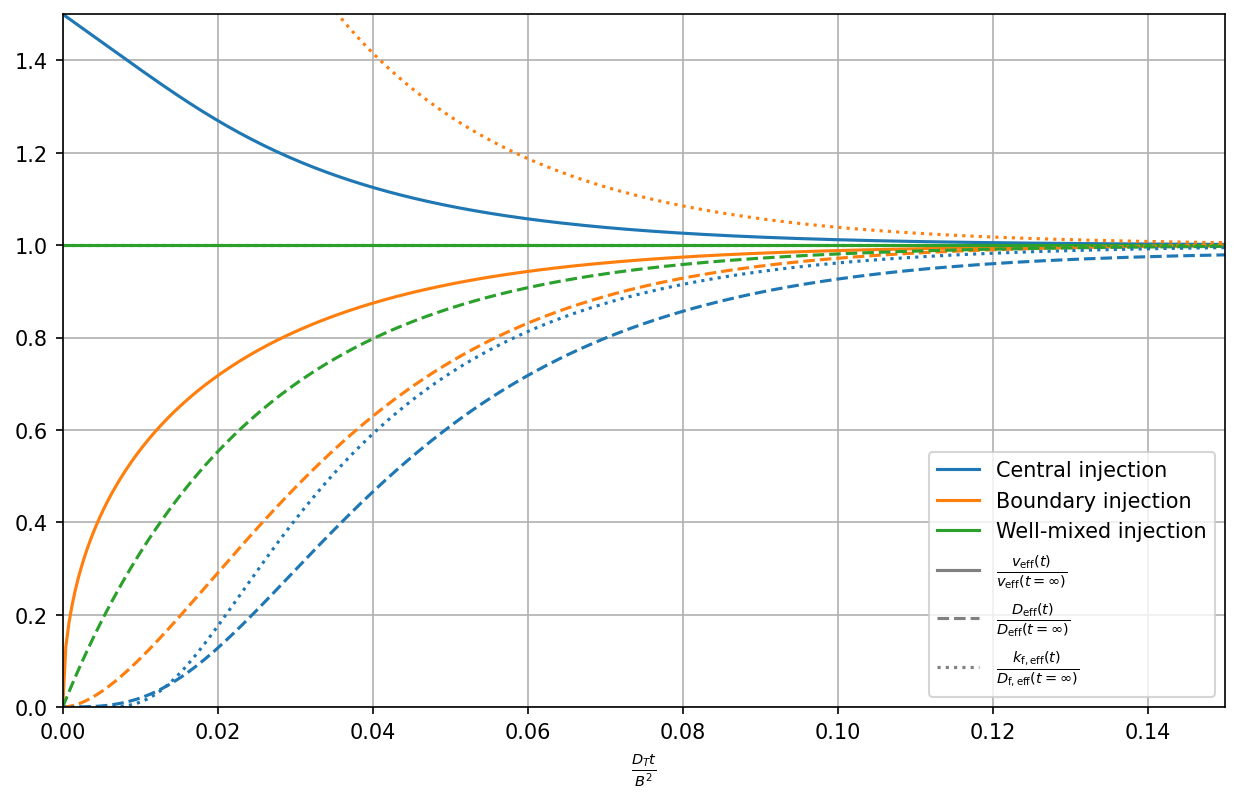

In [20]:
from matplotlib.lines import Line2D

i = 4

handle1, = plt.plot(thetas,v_effs_central[i],color = 'tab:blue',label = 'Central injection')
handle2, = plt.plot(thetas,v_effs_bound[i],color = 'tab:orange',label = 'Boundary injection')
handle3, = plt.plot(thetas,np.ones_like(thetas),color = 'tab:green',label = 'Well-mixed injection')
plt.plot(thetas,D_effs_central[i]*(6*(2*a_s[i]**2+9*a_s[i]+9)),color = 'tab:blue',linestyle = 'dashed')
plt.plot(thetas,D_effs_bound[i]*(6*(2*a_s[i]**2+9*a_s[i]+9)),color = 'tab:orange',linestyle = 'dashed')
plt.plot(thetas,(72/(np.pi**6)*np.sum(1/np.arange(1,10)[:,None]**6*(np.cos(np.arange(1,10)[:,None]*np.pi)+1)**2
                                      *(1-np.exp(-np.arange(1,10)[:,None]**2*np.pi**2*thetas)),axis = 0))
         *(6*(2*a_s[i]**2+9*a_s[i]+9)),color = 'tab:green',linestyle = 'dashed')
plt.plot(thetas,k_effs_central,linestyle = 'dotted',color = 'tab:blue')
plt.plot(thetas,k_effs_bound,linestyle = 'dotted',color = 'tab:orange')
plt.plot(thetas,np.ones_like(thetas),linestyle = 'dotted',color = 'tab:green')

print(a_s[i])

plt.xlim(0,0.15)
plt.ylim(0,1.5)
plt.legend(handles = [handle1,handle2,handle3,
                      Line2D([], [], color='gray', label=r'$\frac{v_{\mathrm{eff}}(t)}{v_{\mathrm{eff}}(t=\infty)}$'),
                      Line2D([], [], color='gray', linestyle = 'dashed', label=r'$\frac{D_{\mathrm{eff}}(t)}{D_{\mathrm{eff}}(t=\infty)}$'),
                      Line2D([], [], color='gray', linestyle = 'dotted', label=r'$\frac{k_{\mathrm{f,eff}}(t)}{D_{\mathrm{f,eff}}(t=\infty)}$')])
plt.xlabel(r'$\frac{D_T t}{B^2}$')
plt.grid()